# Business Problem

##  **1. Membership tier optimization**: Management wants to know if loyalty tiers(Gold,Silver,Bronze) are actually driving higher revenue,or ifd lower-tier members are spending just as much without the perks.

## 2. **Promotional Discounts**: Do discounts drive higher total spend, or do people spend the same regardless?

## 3. **Customer Retension & Churn Risk Identification**: The platform is losing track of repeat buyers. Leadership needs a way to flag which customer are at risk of churning based on how long it has been since their last purchase.

## 4. **Drivers of Customer Satisfaction** : Customers feedback is mixed(Satisfied vs neutral vs Unsatisfied). The business wants to understand what specific factors cause a customer to give "unsatisfied" label.




In [ ]:
# Import libraries
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib.pyplot as plt




In [ ]:
# Load data
df=pd.read_csv('E-commerce Customer Behavior.csv')

In [ ]:
#Preview data
df.head()

,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


In [ ]:
# Dataset size
df.shape

(350, 11)

In [ ]:
# Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               350 non-null    int64  
 1   Gender                    350 non-null    object 
 2   Age                       350 non-null    int64  
 3   City                      350 non-null    object 
 4   Membership Type           350 non-null    object 
 5   Total Spend               350 non-null    float64
 6   Items Purchased           350 non-null    int64  
 7   Average Rating            350 non-null    float64
 8   Discount Applied          350 non-null    bool   
 9   Days Since Last Purchase  350 non-null    int64  
 10  Satisfaction Level        348 non-null    object 
dtypes: bool(1), float64(2), int64(4), object(4)
memory usage: 27.8+ KB


In [ ]:
# Check Missing values
df.isnull().sum()

,0
Customer ID,0
Gender,0
Age,0
City,0
Membership Type,0
Total Spend,0
Items Purchased,0
Average Rating,0
Discount Applied,0
Days Since Last Purchase,0


# DATA CLEANING

In [ ]:
# Check missing values
df.isnull().sum()

,0
Customer ID,0
Gender,0
Age,0
City,0
Membership Type,0
Total Spend,0
Items Purchased,0
Average Rating,0
Discount Applied,0
Days Since Last Purchase,0


In [ ]:
# Drop Missing Rows
df = df.dropna(subset=['Satisfaction Level'])

# Verify they are gone
print(df.isnull().sum())


Customer ID                 0
Gender                      0
Age                         0
City                        0
Membership Type             0
Total Spend                 0
Items Purchased             0
Average Rating              0
Discount Applied            0
Days Since Last Purchase    0
Satisfaction Level          0
dtype: int64


In [ ]:
# Check duplicates
df.duplicated().sum()

np.int64(0)

In [ ]:
# check datatypes
df.dtypes

,0
Customer ID,int64
Gender,object
Age,int64
City,object
Membership Type,object
Total Spend,float64
Items Purchased,int64
Average Rating,float64
Discount Applied,bool
Days Since Last Purchase,int64


### Solve Business Questions

  Membership Type  Total Spend
0          Bronze   474.223684
1            Gold  1311.144444
2          Silver   748.432479


/tmp/ipykernel_614/1613610487.py:7: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data = df, x='Membership Type', y='Total Spend',palette = 'viridis', ci=None)
/tmp/ipykernel_614/1613610487.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = df, x='Membership Type', y='Total Spend',palette = 'viridis', ci=None)


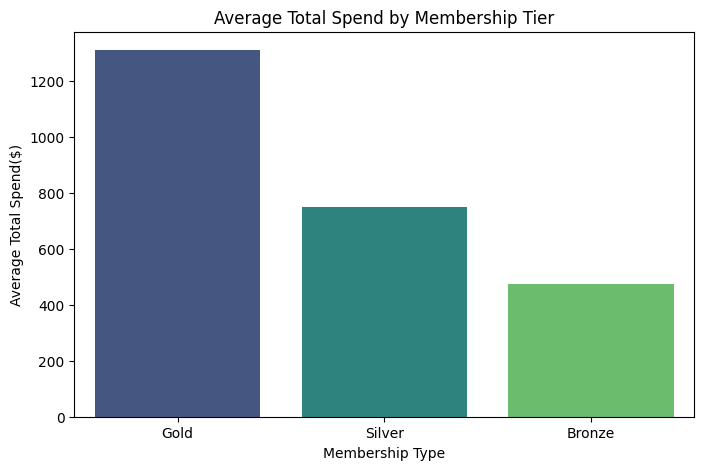

In [ ]:
# Calculate average spend per membership type
Membership_Summary = df.groupby('Membership Type')['Total Spend'].mean().reset_index()
print(Membership_Summary)

 #Plot results
plt.figure(figsize=(8,5))
sns.barplot(data = df, x='Membership Type', y='Total Spend',palette = 'viridis', ci=None)
plt.title('Average Total Spend by Membership Tier')
plt.xlabel('Membership Type')
plt.ylabel('Average Total Spend($)')
plt.show()

## **Membership Tier Analysis Insights**
# There's a massive jump in spending power for Gold tier Customers,this proves that membership tier  system works effictvely to lock in high value buyers

--- Average Spend:Discount vs No Dicount---
   Discount Applied  Total Spend
0             False   909.012139
1              True   787.273714


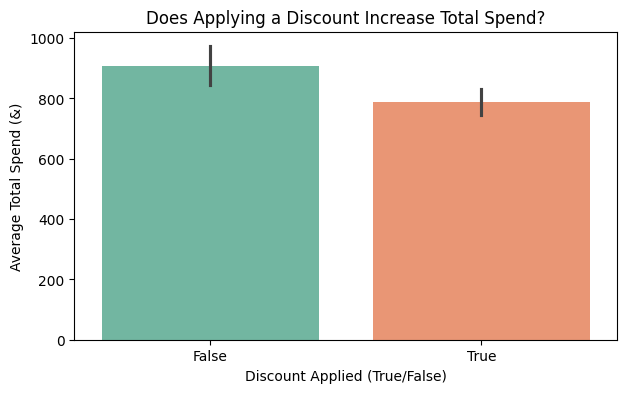

In [ ]:
# Compare average spend between customers  who get a discount and those who don't
discount_summary = df.groupby('Discount Applied')['Total Spend'].mean().reset_index()
print("--- Average Spend:Discount vs No Dicount---")
print(discount_summary)

#plot
plt.figure(figsize=(7,4))
sns.barplot(data=df, x = 'Discount Applied', y='Total Spend', hue='Discount Applied',palette='Set2', legend=False)
plt.title('Does Applying a Discount Increase Total Spend?')
plt.xlabel('Discount Applied (True/False)')
plt.ylabel('Average Total Spend (&)')
plt.show()

## **Promotional Discount Insights**
# Contrary to popular beliefs, customers who buy without a discount actually spend more on average than those who receive discount.This suggests that heavy discounting might be attracting lower -value bargain shoppers rather than increasing overal cart size.

---Average Days Since Last Purchase by Satisfaction---
  Satisfaction Level  Days Since Last Purchase
0            Neutral                 19.289720
1          Satisfied                 17.696000
2        Unsatisfied                 42.982759


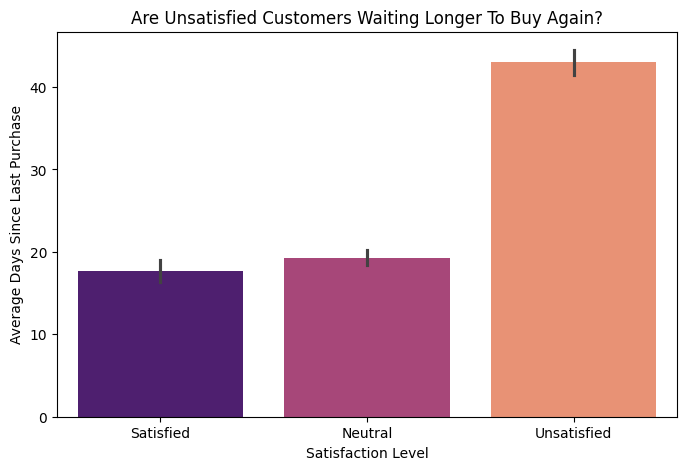

In [ ]:
# See what satisfaction categories exist and their average day since last purchase
churn_summary = df.groupby('Satisfaction Level')['Days Since Last Purchase'].mean().reset_index()
print("---Average Days Since Last Purchase by Satisfaction---")
print(churn_summary)

#Visualize
plt.figure(figsize=(8,5))
sns.barplot(data=df,x='Satisfaction Level', y='Days Since Last Purchase', hue='Satisfaction Level',palette='magma',legend=False)
plt.title('Are Unsatisfied Customers Waiting Longer To Buy Again?')
plt.xlabel('Satisfaction Level')
plt.ylabel('Average Days Since Last Purchase')
plt.show()

# There's dramatic drop-off in engagement for unsatisfied customers.They take more than twice as long to return, this means low satisfaction is direct indicator of impending churn.

---Churn Risk Counts---
Churn_Risk
Low Risk     232
High Risk    116
Name: count, dtype: int64

---Churn Risk Percentage---
Churn_Risk
Low Risk     66.666667
High Risk    33.333333
Name: proportion, dtype: float64


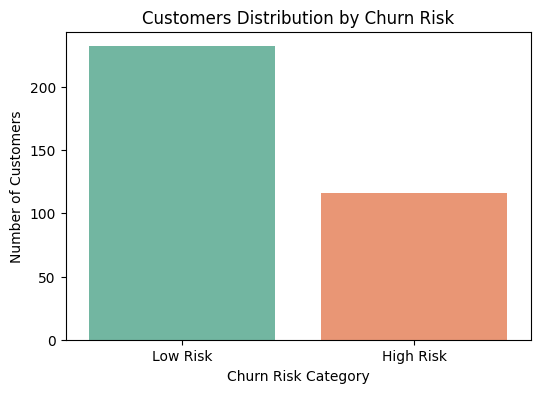

In [ ]:
 #create churn risk column
 df['Churn_Risk'] = 'Low Risk'
 df.loc[df['Satisfaction Level'] == 'Unsatisfied','Churn_Risk'] = 'High Risk'

#print out counts and percentage
print("---Churn Risk Counts---")
print(df['Churn_Risk'].value_counts())

print("\n---Churn Risk Percentage---")
print(df['Churn_Risk'].value_counts(normalize=True) *100)

#plot
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn_Risk', hue='Churn_Risk',palette='Set2',legend=False)
plt.title('Customers Distribution by Churn Risk')
plt.xlabel('Churn Risk Category')
plt.ylabel('Number of Customers')
plt.show()

# Applying a rule based classification flagged 33.33%(116 customer) as High risk,while66.6%(232 customers remained at low risk.

## **BUSINESS TAKEAWAY**
#### Targetted re-engagement campaigns eg( personalized follow ups,customer support reach outs) directed at high risk segment can help prevent churn before customer leave permanently